# **DAPR 2026 · Final session: analyzing our own data**
**Data Analysis and Pattern Recognition** · UPC · EEBE

**Professor:** Christian Mata Miquel

**Contact:** christian.mata@upc.edu

Today, we will use the answers from our course survey (`DAPR_2026.csv`) as a real-world dataset to revisit the main ideas from DAPR. The goal is not just to run algorithms: it is to **ask good questions, interpret the results, and recognize their limitations**.

### By the end of this session, you should be able to
- Choose visualizations that reveal distributions, differences, and relationships.
- Explain why missing-value handling, encoding, and standardization matter.
- Interpret PCA in terms of explained variance, component directions, and information loss.
- Compare clustering solutions without assuming that every cluster is a meaningful “type”.
- Communicate conclusions carefully: **correlation is not causation**.

### Roadmap
1. **Explore the data** (S2): what can we learn before modelling?
2. **Prepare features** (S5): missing values, scaling, encoding, and redundancy.
3. **Reduce dimensions with PCA** (S5): how many components, and what do they mean?
4. **Explore clusters** (S3): do any useful patterns emerge?
5. **Team challenges**: apply the methods and defend your interpretation.
6. **Wrap-up**: what can we conclude—and what should we not claim?

> **How to use this notebook:** run the cells in order. Use the sliders and dropdowns to explore the results live. For each challenge, discuss your approach before opening the solution.
>
> **Data note:** the notebook uses `DAPR_2026.csv` if it is available. Otherwise, it tries `DAPR_2026_synthetic.csv`. Synthetic data are simulated and must not be presented as actual student feedback.
>
> **Privacy and respect:** use only aggregated patterns, do not try to identify individual students, and treat responses about the professor and classmates respectfully.


## 0. Setup and data loading

Before analysing anything, check which dataset is being used and how many responses it contains. If you are using the real survey, remember that even a dataset without names can contain indirectly identifying information.

**Instructor tip:** allow students a minute to predict what they expect to find before showing the first plot.


In [1]:
#Connect to Google Drive (if it is necessary)
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [5]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from ipywidgets import interact, IntSlider, Dropdown
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from matplotlib.ticker import MaxNLocator

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

FILE = "DAPR_2026_Survey.csv"                       # real file exported from Google Sheets

## Data preview

In [9]:
# The survey's column names are long sentences; we rename them by position.
# This relies on the exported CSV keeping the same column order.
CODES = ['group', 'program', 'age', 'sex', 'region', 'studies', 'prog_years', 'conf_python', 'conf_statistics', 'conf_algebra', 'conf_data', 'sat_content', 'sat_usefulness', 'sat_labs', 'sat_pace', 'sat_materials', 'sat_assessment', 'sat_support', 'sat_workload', 'sat_flipped', 'sat_innovation', 'sat_overall', 'recommend', 'int_visualization', 'int_clustering', 'int_pca', 'study_hours', 'prof_entertaining', 'prof_approachable', 'prof_engaging', 'prof_will_miss', 'prof_dinner', 'prof_applause', 'nights_out', 'sport_days', 'coffees_day', 'sleep_hours', 'comment']
raw = pd.read_csv(FILE, keep_default_na=False, na_values=[""])   # blank answers are missing; literal "None" is kept
assert raw.shape[1] == len(CODES) + 1, f"Expected {len(CODES) + 1} columns but found {raw.shape[1]}"
df = raw.copy()
df.columns = ["timestamp"] + CODES

# These fields are not needed for the analysis. Drop them before displaying or processing the data.
# *** Example: We can consider for privacity that the final comment will be not included. ***
df = df.drop(columns=["timestamp", "comment"])
print(f"{len(df)} responses, {df.shape[1]} analysis columns")

# Show the first 5 rows (where only T11 is visible due to chronological order)
print("--- First 5 rows (head) ---")
display(df[["group", "sat_overall"]].head())

# Show the last 5 rows (where other groups like T22 appear)
print("\n--- Last 5 rows (tail) ---")
display(df[["group", "sat_overall"]].tail())


68 responses, 37 analysis columns
--- First 5 rows (head) ---


,group,sat_overall
0,T12,3
1,T11,4
2,T11,4
3,T11,4
4,T12,4



--- Last 5 rows (tail) ---


,group,sat_overall
63,T22,5
64,T21,4
65,T21,2
66,T22,5
67,T21,5


### Explanation of the Data Loading and Cleaning Step

To ensure our data is ready for analysis and respects everyone's privacy, we perform the following steps:

1. **Column Renaming**: The raw survey column names are long sentences from the Google Form. We map them to shorter, standardized codes (like `group`, `prog_years`, `sat_overall`) based on their column positions.
2. **Privacy and Anonymization (`df.drop`)**:
   * **`timestamp`**: We drop this column because the exact time a student submitted the form could be used to cross-reference and identify them.
   * **`comment`**: Free-text comments may contain personal anecdotes, names, or specific details. Dropping them guarantees complete student anonymity during the quantitative analysis.
3. **Quick Summary**: We print the number of responses (rows) and variables (columns) left for analysis.
4. **Data Preview (`.head()`)**: We use `.head()` to show only the first 5 rows of selected columns. *Note: If you only see 'T11' in this preview, it is simply because the first few submissions happened to be from that group. As verified below, all other groups (T12, T21, T22) are successfully loaded!*

In [10]:
# How many students for each group?
display(df['group'].value_counts())

,count
group,
T11,30
T12,18
T21,16
T22,4


### Visualize and Preprocessing the data

In [11]:
#  Ordinal variables -> numbers (label encoding is appropriate because they have a natural order)
ORD_PROG = {"No experience": 0, "Less than 1 year": 1, "1-3 years": 2, "3-5 years": 3, "More than 5 years": 4}
ORD_AGE = {"Under 23": 0, "23-25": 1, "26-28": 2, "29-31": 3, "32 or older": 4}      # 'Prefer not to say' -> NaN
df["prog_years_num"] = df["prog_years"].map(ORD_PROG)
df["age_num"] = df["age"].map(ORD_AGE)

PROGRAM_KEYS = [("Interdisciplinary", "Interdisciplinary"), ("Chemical", "Chemical"), ("Polymers", "Polymers"),
                ("EMSSE", "EMSSE"), ("IMFSE", "IMFSE"), ("Biomedical", "Adv. Biomedical"),
                ("HySet", "HySet"), ("AMASE", "AMASE")]
def short_program(text):
    t = str(text).lower()
    for key, short in PROGRAM_KEYS:
        if key.lower() in t:
            return short
    return "Other"
df["program_short"] = df["program"].map(short_program)
df["section"] = df["group"].astype(str).str[:2]            # T11, T12 -> T1 ; T21, T22 -> T2

CONF = ["conf_python", "conf_statistics", "conf_algebra", "conf_data"]
SAT = ["sat_content", "sat_usefulness", "sat_labs", "sat_pace", "sat_materials", "sat_assessment",
       "sat_support", "sat_workload", "sat_flipped", "sat_innovation", "sat_overall", "recommend"]
INT = ["int_visualization", "int_clustering", "int_pca"]
PROF = ["prof_entertaining", "prof_approachable", "prof_engaging", "prof_will_miss", "prof_dinner", "prof_applause"]  # "about the professor" block
LIFE = ["nights_out", "sport_days", "coffees_day", "sleep_hours"]   # lifestyle
NUM = CONF + SAT + INT + ["prog_years_num", "study_hours"] + PROF + LIFE   # numerical block for PCA and clustering
CAT = ["section", "group", "program_short", "sex", "region", "studies"]    # categorical, to color and compare

# Missing values: The flipped classroom question ('sat_flipped') was optional and contains missing values.
# We handle this by imputing the missing values with the median of the variable (S5: impute, replace or remove).
missing = df[NUM].isna().sum()
missing = missing[missing > 0]
print("Missing values per variable:", missing.to_dict() if len(missing) else "none")

df[NUM] = df[NUM].fillna(df[NUM].median())
print("Numerical variables for the analysis:", len(NUM))
print(df["group"].value_counts().sort_index().to_dict(), "|", df["program_short"].value_counts().to_dict())

Missing values per variable: {'sat_flipped': 2}
Numerical variables for the analysis: 31
{'T11': 30, 'T12': 18, 'T21': 16, 'T22': 4} | {'Chemical': 35, 'Interdisciplinary': 18, 'EMSSE': 7, 'Other': 7, 'IMFSE': 1}


### Check the answers with NaN values

In [12]:
import pandas as pd
# Analyze the original 'raw' dataframe to identify which questions contain null (missing) values
null_counts = raw.isna().sum()
optional_columns = null_counts[null_counts > 0]

if len(optional_columns) > 0:
    print("Optional questions detected in the original survey (with missing values):")
    for col, count in optional_columns.items():
        print(f"- Column: '{col}' | Missing responses: {count}")
else:
    print("No columns with missing values were detected in the currently loaded file.")

Optional questions detected in the original survey (with missing values):
- Column: '20. The flipped classroom experience was useful.' | Missing responses: 2
- Column: '38. Free comment (optional)
' | Missing responses: 37


## **1. Data visualization (S2)**

**Golden rule:** before computing anything, *look at the data*. A summary statistic can hide skew, outliers, subgroups, or missing responses.

As you explore, ask:
- What is the distribution—not just the average?
- Are apparent differences large enough to be interesting, given the number of responses?
- Could one unusual observation or a small subgroup change the story?


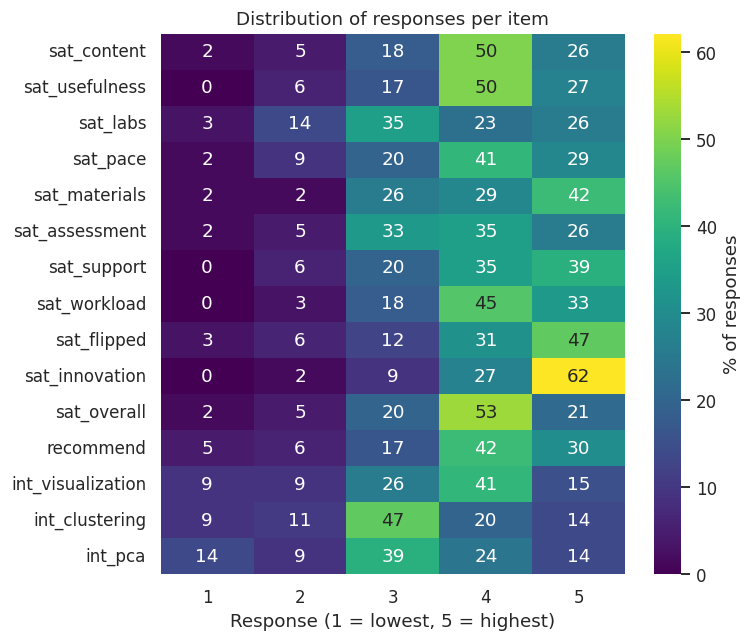

In [ ]:
# How are the responses to each item distributed? (perceptually uniform sequential palette: viridis)
dist = df[SAT + INT].apply(lambda s: s.value_counts(normalize=True).reindex([1, 2, 3, 4, 5], fill_value=0)).T * 100
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(dist, annot=True, fmt=".0f", cmap="viridis", cbar_kws={"label": "% of responses"}, ax=ax)
ax.set_xlabel("Response (1 = lowest, 5 = highest)"); ax.set_title("Distribution of responses per item")
plt.tight_layout(); plt.show()

**Explore live:** choose a variable and a grouping variable. Try the lifestyle variables (`nights_out`, `sport_days`, `coffees_day`, `sleep_hours`).

The points show individual responses; the boxplot summarizes the distribution.

**Discussion prompt:** what do you notice, and what would you need to know before drawing a conclusion?


In [13]:
def compare(variable="sat_overall", by="group"):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.boxplot(data=df, x=by, y=variable, ax=ax, color="lightgray", fliersize=0)
    sns.stripplot(data=df, x=by, y=variable, hue=by, palette="viridis", size=6, alpha=.8, legend=False, ax=ax)
    ax.set_title(f"{variable} by {by}"); plt.xticks(rotation=20, ha="right")
    plt.tight_layout(); plt.show()

interact(compare, variable=Dropdown(options=NUM, value="sat_overall"), by=Dropdown(options=CAT, value="group"));

interactive(children=(Dropdown(description='variable', index=14, options=('conf_python', 'conf_statistics', 'c…

### Understanding the Pearson Correlation Heatmap

To identify linear relationships among our 31 numerical variables, we compute the **Pearson correlation coefficient ($r$)** for every pair and visualize them using a heatmap:

* **The Scale ($r$ range from $-1$ to $+1$):**
  * $r = 1$ indicates a perfect positive linear relationship (as one variable increases, the other increases proportionally).
  * $r = -1$ indicates a perfect negative linear relationship (as one variable increases, the other decreases proportionally).
  * $r = 0$ indicates no linear association.

* **Visualizing with a Diverging Palette (`cmap="vlag"`):**
  * We center the colorbar at **0** so that neutral or near-zero correlations appear in a neutral color (light gray/white).
  * Positive correlations diverge toward one color (blue) and negative correlations toward another (red). This makes strong associations instantly stand out.

* **Crucial Caveat:** **Correlation is not causation!** A high correlation between two variables (e.g., student satisfaction and sleep hours) does not mean one causes the other. They might both be influenced by a third hidden factor (a confounding variable, like workload).

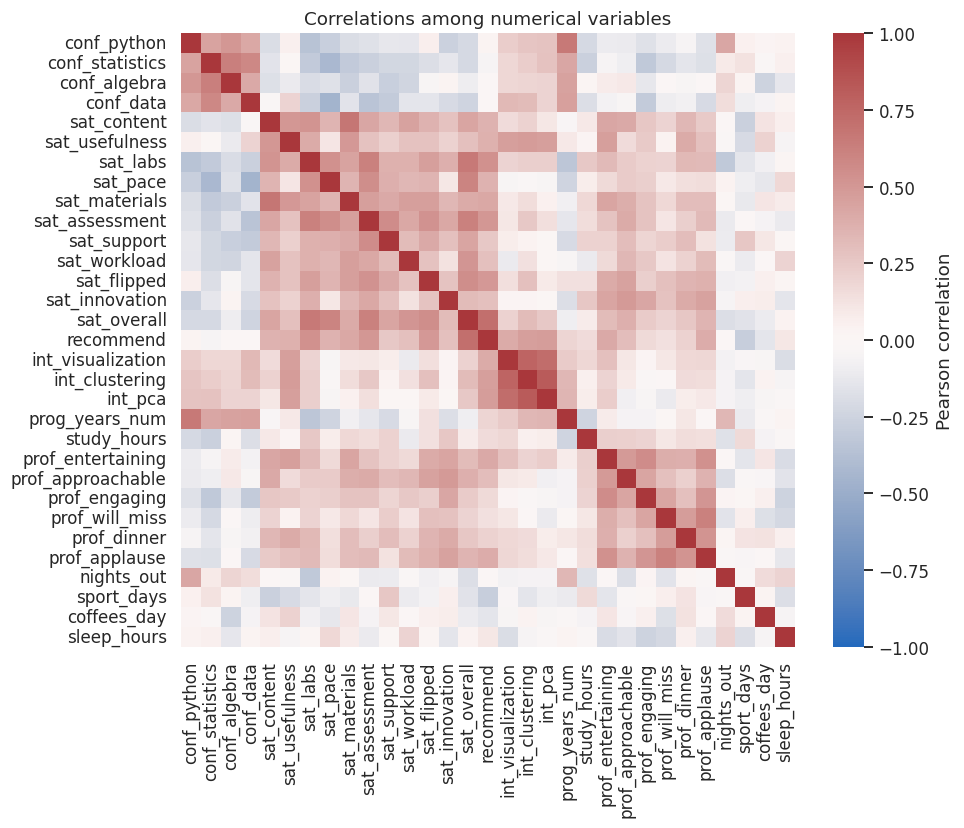

In [14]:
# Correlation matrix: diverging palette centered at 0
# Filter NUM to only include columns that actually exist in df
existing_num = [col for col in NUM if col in df.columns]

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(df[existing_num].corr(), cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlations among numerical variables"); plt.tight_layout(); plt.show()

### List the 10 most correlated pairs of variables

In [15]:
# Calculate the Pearson correlation matrix for numerical variables actually present in df
existing_num = [col for col in NUM if col in df.columns]
corr_matrix = df[existing_num].corr()

# Get the upper triangle of the correlation matrix to avoid duplicates and self-correlations
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Stack and sort the pairs by their absolute correlation value
stacked_corr = upper_tri.stack()
top_10_correlations = stacked_corr.reindex(stacked_corr.abs().sort_values(ascending=False).index).head(10)

# Display the top 10 most correlated pairs
print("--- Top 10 Most Correlated Pairs of Variables ---")
for (var1, var2), coef in top_10_correlations.items():
    print(f"{var1:<20} <-> {var2:<20} | r = {coef:+.3f}")

--- Top 10 Most Correlated Pairs of Variables ---
int_clustering       <-> int_pca              | r = +0.815
int_visualization    <-> int_clustering       | r = +0.771
int_visualization    <-> int_pca              | r = +0.723
sat_overall          <-> recommend            | r = +0.711
sat_content          <-> sat_materials        | r = +0.676
sat_labs             <-> sat_overall          | r = +0.658
conf_python          <-> prog_years_num       | r = +0.657
conf_statistics      <-> conf_algebra         | r = +0.627
sat_assessment       <-> sat_overall          | r = +0.624
prof_will_miss       <-> prof_applause        | r = +0.620


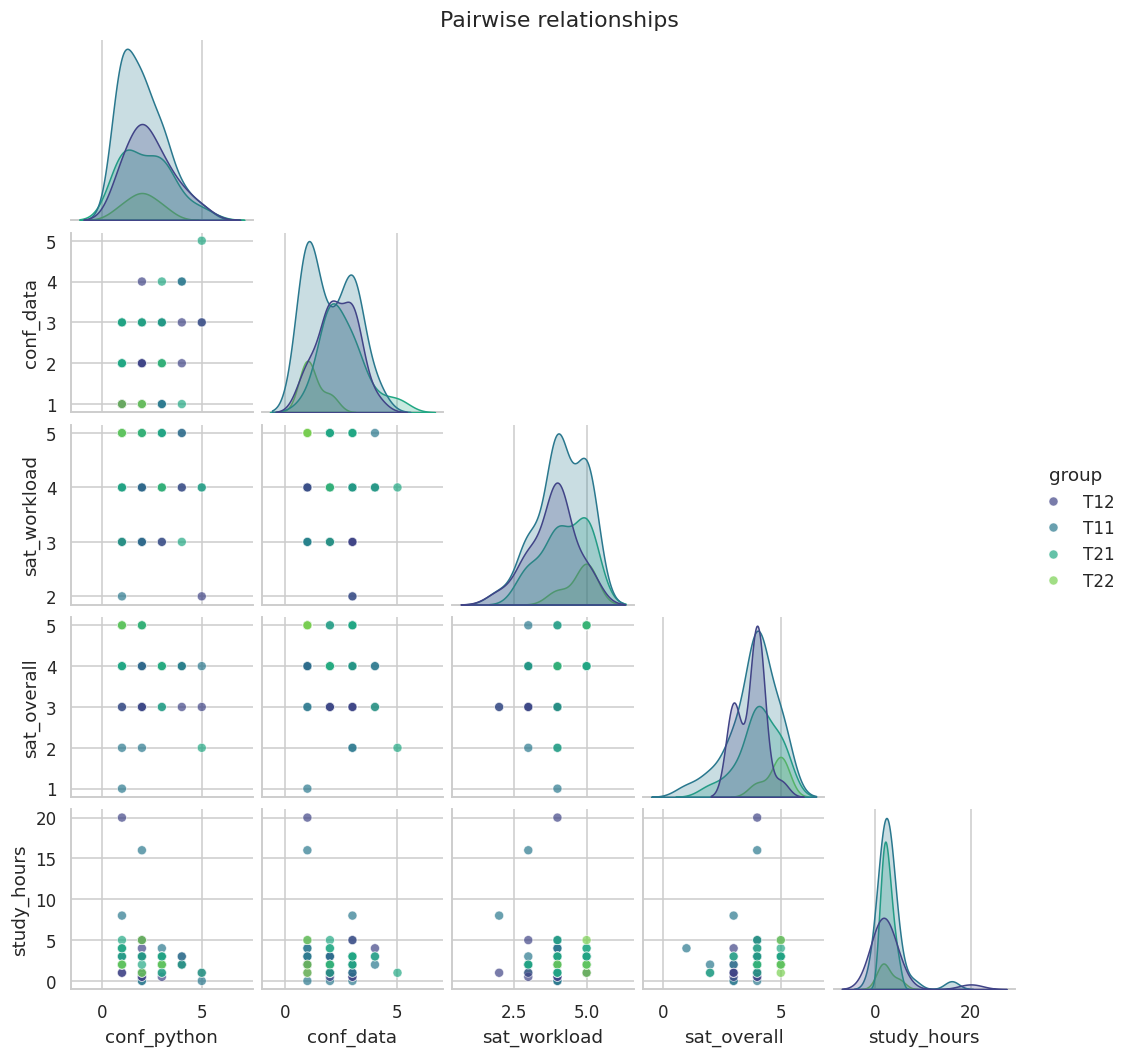

In [16]:
# Scatter plot matrix (SPLOM) of a few variables, colored by group
g = sns.pairplot(df, vars=["conf_python", "conf_data", "sat_workload", "sat_overall", "study_hours"],
                 hue="group", palette="viridis", corner=True, plot_kws=dict(alpha=.7, s=35), height=1.9)
g.figure.suptitle("Pairwise relationships", y=1.01); plt.show()

### How to Read a Scatter Plot Matrix (SPLOM)

A Scatter Plot Matrix might look complex at first glance, but it is just a grid of individual charts that lets us see two things at once: **individual distributions** and **pairwise relationships**.

Here is how to read it step-by-step:

1. **The Diagonal (Density Curves):**
   * Follow the diagonal from top-left to bottom-right.
   * These charts show the distribution (using Kernel Density Estimation) of a single variable at a time (e.g., `conf_python` or `study_hours`), split by student groups (`T11`, `T12`, `T21`, `T22`).

2. **Off-Diagonal Plots (Scatter Plots):**
   * Every other cell in the grid is a scatter plot comparing two different variables.
   * To read a plot, look at the variable name on its far left (Y-axis) and the variable name at the very bottom (X-axis). For example, finding where `study_hours` (Y) and `sat_overall` (X) meet shows you if students who study more hours tend to have higher overall satisfaction.

3. **The Corner Format (`corner=True`):**
   * Since comparing Variable A vs. Variable B is the same as comparing Variable B vs. Variable A, the top half of the grid would just be a mirrored duplicate. We hide it to keep the visualization clean and easy to read!

## **2. Feature preparation (S5)**

- **Missing values:** the flipped-classroom item is optional. Here, blank numerical values are imputed with the median; this is a modelling choice, not a neutral step.
- **Scaling:** PCA and k-means depend on variance and distance. Without standardization, variables with larger numerical scales (such as `study_hours`) can dominate.
- **Encoding:** ordinal categories can be mapped to ordered numbers when that assumption is defensible. Nominal categories need a different representation, such as one-hot encoding, which increases the number of features.
- **Selection vs. extraction:** inspect redundancy first; PCA then creates new axes that summarize variation in the original features.

**Think first:** which of these decisions could change the conclusions?

In [21]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Ensure program_short exists
if "program_short" not in df.columns and "program" in df.columns:
    PROGRAM_KEYS = [("Interdisciplinary", "Interdisciplinary"), ("Chemical", "Chemical"), ("Polymers", "Polymers"),
                    ("EMSSE", "EMSSE"), ("IMFSE", "IMFSE"), ("Biomedical", "Adv. Biomedical"),
                    ("HySet", "HySet"), ("AMASE", "AMASE")]
    def short_program(text):
        t = str(text).lower()
        for key, short in PROGRAM_KEYS:
            if key.lower() in t:
                return short
        return "Other"
    df["program_short"] = df["program"].map(short_program)

print("Variance of each variable BEFORE standardizing (very different scales!):")
existing_num = [col for col in NUM if col in df.columns]
# Fill NaN values dynamically to avoid propagation of NaNs after standardizing
df[existing_num] = df[existing_num].fillna(df[existing_num].median())

print(df[existing_num].var().round(2).sort_values(ascending=False).head(5).to_string())

scaler = StandardScaler()
X = scaler.fit_transform(df[existing_num])          # mean 0 and standard deviation 1 in every column
print("\nAfter standardizing -> max |mean|:", np.abs(X.mean(0)).max().round(6), "| standard deviations:", np.unique(X.std(0).round(3)))

# Redundancy: highly correlated pairs (candidates to merge or drop)
c = df[existing_num].corr().abs()
pairs = c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
high = pairs[pairs > 0.7]
print("\nPairs with |r| > 0.7:", "none" if high.empty else "")
if not high.empty:
    print(high.round(2).to_string())

# The cost of encoding nominal variables with one-hot
existing_cat = [col for col in ["program_short", "sex", "region", "studies"] if col in df.columns]
onehot = pd.get_dummies(df[existing_cat])
print(f"\nOne-hot of {len(existing_cat)} nominal variables: from {len(existing_cat)} columns to {onehot.shape[1]} columns")

Variance of each variable BEFORE standardizing (very different scales!):
study_hours    9.24
sport_days     3.52
nights_out     2.01
coffees_day    1.92
int_pca        1.40

After standardizing -> max |mean|: 0.0 | standard deviations: [1.]

Pairs with |r| > 0.7: 
int_clustering     int_pca           0.81
int_visualization  int_clustering    0.77
                   int_pca           0.72
sat_overall        recommend         0.71

One-hot of 4 nominal variables: from 4 columns to 23 columns


## **3. PCA (S5)**

PCA finds orthogonal directions that explain as much variance as possible. For standardized variables, PCA is equivalent to analysing the correlation matrix.

- **Eigenvectors** define the component directions.
- **Eigenvalues** (λ) quantify the variance along those directions.
- The sum of the eigenvalues equals the number of standardized variables.

PCA is useful for compression and visualization, but a component is a mathematical combination of variables—not automatically a meaningful real-world concept. The sign of a component is arbitrary.


Total variance = 31.00  (number of variables = 31)
Components for >= 80 %: 12   |   Kaiser criterion (λ > 1): 9   ->  they do NOT agree


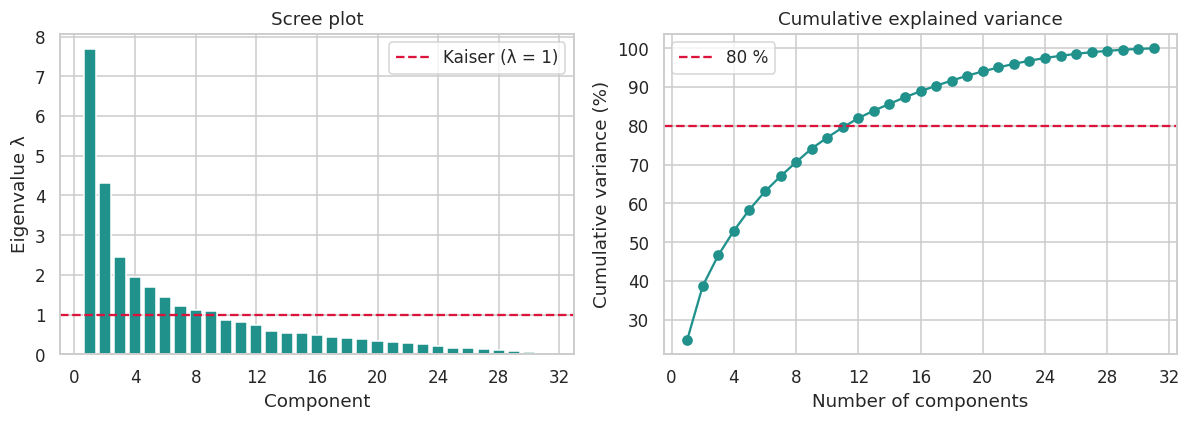

In [22]:
# Eigenvalues of the correlation matrix, sorted from largest to smallest (always sort before accumulating!)
lam = np.sort(np.linalg.eigvalsh(np.corrcoef(X.T)))[::-1]
pct = lam / lam.sum() * 100
cum = np.cumsum(pct)
M80 = int(np.argmax(cum >= 80) + 1)          # number of components needed for >= 80 % of the variance
MK = int((lam > 1).sum())                    # Kaiser criterion (λ > 1)
print(f"Total variance = {lam.sum():.2f}  (number of variables = {len(NUM)})")
print(f"Components for >= 80 %: {M80}   |   Kaiser criterion (λ > 1): {MK}   ->  {'they agree' if M80 == MK else 'they do NOT agree'}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(range(1, len(lam) + 1), lam, color=sns.color_palette("viridis", 1)[0])
ax[0].axhline(1, color="crimson", ls="--", label="Kaiser (λ = 1)")
ax[0].set(xlabel="Component", ylabel="Eigenvalue λ", title="Scree plot"); ax[0].legend()
ax[1].plot(range(1, len(lam) + 1), cum, "o-", color=sns.color_palette("viridis", 1)[0])
ax[1].axhline(80, color="crimson", ls="--", label="80 %")
ax[1].set(xlabel="Number of components", ylabel="Cumulative variance (%)", title="Cumulative explained variance"); ax[1].legend()
for a in ax: a.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

### 💡 Quick Guide: Understanding the Scree Plot Output

* **Total variance = 31.00:** Since we standardized our data, each of the 31 original variables has a variance of exactly $1.0$. Therefore, the total system variance to be explained is exactly $31$.

* **80% Variance Criterion (13 components):** This approach prioritizes **reconstruction accuracy**. To preserve at least 80% of the original information ($24.8$ out of $31$ units of variance), we must keep the first 13 principal components. Keeping fewer components simplifies our model but results in a higher loss of information.

### **How many Principal Components are there in total?**

Before analyzing the plots, keep this fundamental rule of PCA in mind:
* **Total Components = Total Numerical Features**
* Since our dataset contains **31 numerical variables** (`NUM`), the PCA algorithm initially calculates exactly **31 Principal Components**.
* When we use sliders to select $M=3$ or view only `PC1`, `PC2`, and `PC3`, we are choosing to **project and visualize** our data using only the most informative dimensions, discarding the remaining ones.

**Explore live:** change the number of retained components, M.

For this standardized dataset, total variance is split into **captured variance + reconstruction error**. More components generally improve reconstruction, but the goal is to balance simplicity with information retained.


In [23]:
# The maximum value of M is 31
def reconstruct(M=3):
    p = PCA(n_components=M).fit(X)
    Xr = p.inverse_transform(p.transform(X))
    err = ((X - Xr) ** 2).sum() / (X ** 2).sum() * 100
    print(f"M = {M} components -> captured variance = {100 - err:.1f} %  |  reconstruction error = {err:.1f} %")
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.bar(["Captured", "Error"], [100 - err, err], color=[sns.color_palette("viridis", 3)[0], sns.color_palette("viridis", 3)[2]])
    ax.set_ylabel("% of total variance"); ax.set_ylim(0, 100); plt.tight_layout(); plt.show()

interact(reconstruct, M=IntSlider(min=1, max=len(NUM), step=1, value=2));

interactive(children=(IntSlider(value=2, description='M', max=31, min=1), Output()), _dom_classes=('widget-int…

### 💡 Quick Guide: What happens when we change $M$?

* **What is $M$?**  
  $M$ is the number of **Principal Components** we choose to keep. Think of it as a "budget" for compressing our 31 original variables.

* **Increasing $M$ (e.g., keeping 15 components):**  
  * **Captured Variance increases:** We preserve almost all the original details.
  * **Reconstruction Error drops:** If we try to recreate the original dataset from these components, the result is almost identical to the raw data.
  * *Trade-off:* We lose the benefits of dimensionality reduction (it's hard to visualize or simplify 15 dimensions!).

* **Decreasing $M$ (e.g., keeping only 2 components):**  
  * **Captured Variance decreases:** We discard minor details and keep only the most dominant patterns.
  * **Reconstruction Error rises:** Recreating the original 31 variables from just 2 components will yield an approximate, "blurry" version of the data.
  * *Benefit:* Maximum simplicity! We can easily plot the students on a 2D scatter plot (Biplot) and find general patterns.

### **How many PCA?**

In [24]:
def show_loadings(num_pcs=3):
    # Final PCA fit and loadings.
    pca = PCA().fit(X)
    scores = pca.transform(X)
    columns = [f"PC{i}" for i in range(1, num_pcs + 1)]
    loadings = pd.DataFrame(
        pca.components_[:num_pcs].T,
        index=NUM,
        columns=columns
    )
    fig, ax = plt.subplots(figsize=(1.5 + num_pcs * 1.2, 7.5))
    sns.heatmap(
        loadings.sort_values("PC1"),
        cmap="vlag",
        center=0,
        annot=True,
        fmt=".2f",
        cbar_kws={"label": "Loading"},
        ax=ax
    )
    ax.set_title(f"Variable loadings on PC1-PC{num_pcs}")
    plt.tight_layout()
    plt.show()

interact(
    show_loadings,
    num_pcs=IntSlider(
        min=2, max=10, step=1, value=3,
        description="Show PCs"
    )
);

interactive(children=(IntSlider(value=3, description='Show PCs', max=10, min=2), Output()), _dom_classes=('wid…

### 🔍 **Interpreting PCA Loadings: What to look for?**

The heatmap below shows the **loadings** (coefficients) of our 31 variables on the first three principal components (PC1, PC2, and PC3).

To interpret what each component represents, look for:

1. **High absolute values (close to $+1.0$ or $-1.0$):** These variables contribute the most to that component's direction. For example, if many satisfaction ratings cluster together with high positive values on PC1, PC1 can be interpreted as a general "Course Satisfaction" dimension.
2. **Opposing signs (Positive vs. Negative):** If one variable has a high positive loading and another has a high negative loading, they pull the component in opposite directions, indicating a contrast (e.g., studying hours vs. sleeping hours).
3. **Arbitrary signs:** Remember that the overall sign of a component is mathematically arbitrary. If all satisfaction ratings were negative instead of positive, PC1 would still represent "Satisfaction," just with lower values meaning higher satisfaction.

In [25]:
# Fit PCA and calculate scores and explained variance
pca = PCA().fit(X)
scores = pca.transform(X)
pct = pca.explained_variance_ratio_ * 100

In [26]:
def biplot(color_by="group", arrows=8):
    S, L = scores[:, :2], pca.components_[:2].T
    cats = df[color_by].astype(str)
    fig, ax = plt.subplots(figsize=(9, 6.5))

    for cat, col in zip(
        sorted(cats.unique()),
        sns.color_palette("viridis", cats.nunique())
    ):
        m = (cats == cat).values
        ax.scatter(
            S[m, 0], S[m, 1],
            s=45, color=col, alpha=.85, label=cat
        )

    k = 0.85 * np.abs(S).max() / np.abs(L).max()

    for i in np.argsort(np.hypot(L[:, 0], L[:, 1]))[::-1][:arrows]:
        ax.arrow(
            0, 0, L[i, 0] * k, L[i, 1] * k,
            color="black", alpha=.6,
            head_width=.12, length_includes_head=True
        )
        ax.text(
            L[i, 0] * k * 1.08,
            L[i, 1] * k * 1.08,
            NUM[i], fontsize=8
        )

    ax.axhline(0, color="gray", lw=.5)
    ax.axvline(0, color="gray", lw=.5)

    ax.set(
        xlabel=f"PC1 ({pct[0]:.1f} %)",
        ylabel=f"PC2 ({pct[1]:.1f} %)",
        title="Biplot: students and variables"
    )

    ax.legend(
        title=color_by,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8
    )
    plt.tight_layout()
    plt.show()

interact(
    biplot,
    color_by=Dropdown(options=CAT, value="group"),
    arrows=IntSlider(min=3, max=len(NUM), value=8)
);

interactive(children=(Dropdown(description='color_by', index=1, options=('section', 'group', 'program_short', …

### 💡 Quick Guide: How to Read the Biplot

A **Biplot** is a powerful visualization because it projects both our **observations (students)** and our **variables (features)** onto the same 2D space defined by PC1 and PC2.

Here is how to interpret it:

1. **The Dots (Students):**
   * Each dot represents a student.
   * **Closeness means similarity:** Students who are plotted close to each other have very similar survey response profiles.
   * **Distance means difference:** Students on opposite sides of the plot have contrasting response profiles.

2. **The Arrows (Variables):**
   * Each arrow represents one of our original survey variables.
   * **Direction:** The direction of the arrow shows how that variable correlates with PC1 and PC2. For example, if an arrow points far to the right, that variable has a strong positive correlation with PC1.
   * **Length:** The length of the arrow (its magnitude) represents how much of that variable's variance is captured by these first two components. Longer arrows mean the variable is well-represented in this 2D view.
   * **Angles between arrows:**
     * **Sharp angle (pointing in the same direction):** Strong positive correlation between those two variables.
     * **Right angle ($90^\circ$):** No correlation.
     * **Opposite directions ($180^\circ$):** Strong negative correlation.

## 4. Clustering (S3)

Can we find groups of observations with similar profiles? We will run k-means on the first principal components and compare the result with other choices.

Keep in mind:
- Clustering always returns groups, even when the data do not contain clear natural clusters.
- The result depends on the representation, distance, and number of clusters.
- A cluster is a summary of responses—not a label for a person.


Clustering space: the first 3 principal components (80 % criterion: 12; Kaiser: 9)


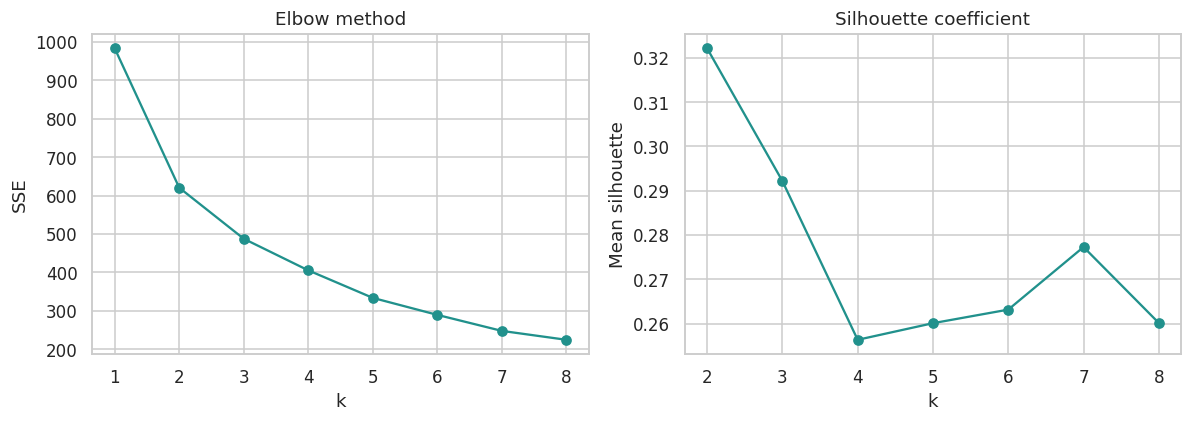

In [27]:
NPC = 3         # number of components used for clustering (adjustable: look at the elbow in the scree plot; try 2, 3, 4 or M80)

# Fix: Explicitly fit PCA globally to define 'scores' in the environment
pca = PCA().fit(X)
scores = pca.transform(X)

X_pc = scores[:, :NPC]
print(f"Clustering space: the first {NPC} principal components (80 % criterion: {M80}; Kaiser: {MK})")

ks = list(range(1, 9))
sse = [KMeans(k, n_init=10, random_state=0).fit(X_pc).inertia_ for k in ks]
sil = [np.nan] + [silhouette_score(X_pc, KMeans(k, n_init=10, random_state=0).fit_predict(X_pc)) for k in ks[1:]]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, sse, "o-", color=sns.color_palette("viridis", 1)[0]); ax[0].set(xlabel="k", ylabel="SSE", title="Elbow method")
ax[1].plot(ks, sil, "o-", color=sns.color_palette("viridis", 1)[0]); ax[1].set(xlabel="k", ylabel="Mean silhouette", title="Silhouette coefficient")
for a in ax: a.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

### 💡 Quick Guide: Understanding the Elbow and Silhouette Plots

To find the most appropriate number of clusters ($k$) for our students, we look at two metrics:

1. **The Elbow Method (Left Plot - SSE):**
   * **SSE (Sum of Squared Errors)** measures how spread out students are inside their clusters. More clusters ($k$) always make this error smaller.
   * **What to look for:** Look for an "elbow" or a bend in the curve (typically at $k=2$ or $k=3$) where the error stops dropping sharply. This point represents a sweet spot where adding more groups gives diminishing returns.

2. **The Silhouette Coefficient (Right Plot):**
   * This score (from $-1$ to $+1$) measures how well-separated the clusters are.
   * **What to look for:** Look for the **highest peak** on the graph. A higher peak (for example, at $k=3$) means students are very close to their own cluster members and far away from other clusters, indicating a mathematically strong and distinct grouping.

In [28]:
PROFILE = ["conf_python", "conf_data", "prog_years_num", "sat_overall", "sat_pace", "sat_workload", "int_pca", "study_hours", "prof_dinner", "nights_out", "sport_days", "sleep_hours"]

def kmeans_live(k=3, space="PCA"):
    E = X_pc if space == "PCA" else X
    lab = KMeans(k, n_init=10, random_state=0).fit_predict(E)
    fig, ax = plt.subplots(figsize=(7, 5.5))
    for c, col in zip(range(k), sns.color_palette("viridis", k)):
        ax.scatter(scores[lab == c, 0], scores[lab == c, 1], s=45, color=col, label=f"Cluster {c}", alpha=.85)
    ax.set(xlabel=f"PC1 ({pct[0]:.1f} %)", ylabel=f"PC2 ({pct[1]:.1f} %)", title=f"k-means (k = {k}) on {space}")
    ax.legend(); plt.tight_layout(); plt.show()
    table = df.assign(cluster=lab).groupby("cluster")[PROFILE].mean().round(2)
    table.insert(0, "n", np.bincount(lab))
    display(table.style.background_gradient(cmap="viridis", axis=0, subset=PROFILE))

interact(kmeans_live, k=IntSlider(min=2, max=6, value=3), space=Dropdown(options=["PCA", "Standardized variables"], value="PCA"));

interactive(children=(IntSlider(value=3, description='k', max=6, min=2), Dropdown(description='space', options…

**Hierarchical clustering:** compare how the dendrogram and merge heights change with the linkage criterion (`single`, `complete`).

**Discuss:** does the dendrogram suggest a clear cut, or are several choices plausible?


In [29]:
def dendro(method="ward"):
    Z = linkage(X_pc, method=method)
    fig, ax = plt.subplots(figsize=(11, 4))
    dendrogram(Z, no_labels=True, ax=ax, color_threshold=0.7 * Z[:, 2].max())
    ax.set(title=f"Dendrogram ({method})", ylabel="Merge height"); plt.tight_layout(); plt.show()

interact(dendro, method=Dropdown(options=["single", "complete"], value="single"));

interactive(children=(Dropdown(description='method', options=('single', 'complete'), value='single'), Output()…

In [30]:
# Is the solution stable? We fit on 80 % of the students and compare with the full solution (ARI: 1 = identical)
def stability(k=3, n=30):
    rng = np.random.default_rng(0)
    base = KMeans(k, n_init=10, random_state=0).fit_predict(X_pc)
    aris = []
    for s in range(n):
        idx = rng.choice(len(X_pc), int(0.8 * len(X_pc)), replace=False)
        lab = KMeans(k, n_init=10, random_state=s).fit(X_pc[idx]).predict(X_pc)
        aris.append(adjusted_rand_score(base, lab))
    return np.mean(aris), np.std(aris)

for k in range(2, 7):
    m, s = stability(k)
    print(f"k = {k}: mean ARI = {m:.2f} ± {s:.2f}")

k = 2: mean ARI = 0.92 ± 0.08
k = 3: mean ARI = 0.62 ± 0.19
k = 4: mean ARI = 0.55 ± 0.17
k = 5: mean ARI = 0.57 ± 0.18
k = 6: mean ARI = 0.64 ± 0.12


##**5. Live challenges**

For each challenge:

1. **Predict:** what do you expect to see?
2. **Analyse:** write or adapt the code and inspect the output.
3. **Interpret:** state one conclusion and one limitation.
4. **Compare:** open the solution and discuss whether another approach would also be valid.

If time is limited, prioritize Challenges 1, 2, 4, 5, 6, and 12; use the others as extension tasks.


# **5.1. Academic Challenges**

### **Challenge 1**· Is overall course satisfaction different in T1 and T2, across the four groups, or between master's programmes?

Report group sizes as well as averages. Are any differences convincing, or could they reflect small sample sizes?


In [ ]:
# Write your proposal here

         mean   std  count
section                   
T1       3.79  0.85     48
T2       4.20  0.83     20
       mean   std  count
group                   
T11    3.83  0.99     30
T12    3.72  0.57     18
T21    4.06  0.85     16
T22    4.75  0.50      4
                   mean   std  count
program_short                       
Chemical           3.74  1.01     35
EMSSE              3.86  0.69      7
IMFSE              4.00   NaN      1
Interdisciplinary  4.11  0.68     18
Other              4.29  0.49      7


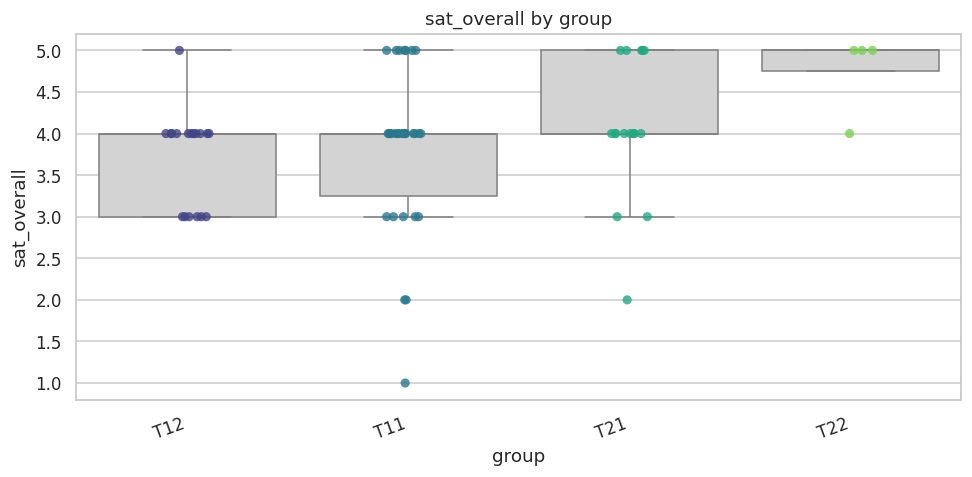

In [31]:
#@title **Solution – challenge 1** { display-mode: "form" }
# Ensure section exists
if "section" not in df.columns and "group" in df.columns:
    df["section"] = df["group"].astype(str).str[:2]

print(df.groupby("section")["sat_overall"].agg(["mean", "std", "count"]).round(2))
print(df.groupby("group")["sat_overall"].agg(["mean", "std", "count"]).round(2))
print(df.groupby("program_short")["sat_overall"].agg(["mean", "std", "count"]).round(2))
compare("sat_overall", "group")

* **Challenge 1 (Overall Satisfaction across Groups):** We observed slight variations in satisfaction levels (`sat_overall`) across groups and programs. For instance, T2 had a mean satisfaction of 4.11 (n=18) compared to T1 with 3.79 (n=48). Looking closer, T22 has a high satisfaction of 4.67 but only 3 responses, while Chemical Engineering has a 3.74 average across 35 students. **Takeaway:** Never generalize trends from very small subgroups without looking at the variance.

### **Challenge 2** · Which course aspects received the lowest ratings?

Rank them with a bar chart (not a pie chart). How many responses are available for each item, and could missing answers affect the ranking?


In [ ]:
# Write your proposal here

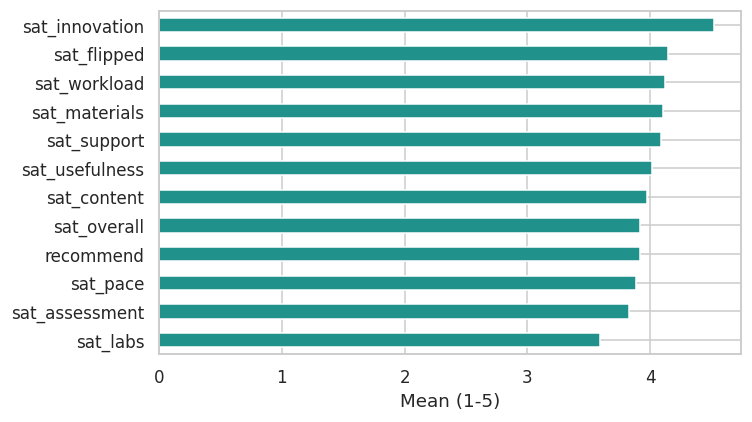

In [32]:
#@title **Solution – challenge 2** { display-mode: "form" }
fig, ax = plt.subplots(figsize=(7, 4))
df[SAT].mean().sort_values().plot(kind="barh", color=sns.color_palette("viridis", 1)[0], ax=ax)
ax.set_xlabel("Mean (1-5)"); plt.tight_layout(); plt.show()

* **Challenge 2 (Lowest Rated Course Aspects):** By plotting the averages in a horizontal bar chart, we easily ranked student concerns. We can see which areas are rated lowest (such as flipped classroom). Since optional questions like `sat_flipped` had 2 missing responses, we must remember that results are based only on those who answered, which could introduce response bias.

### **Challenge 3** · Which pair of numerical variables has the strongest negative correlation?

Plot the pair and propose a possible explanation. Can you distinguish an association from a causal relationship?


In [ ]:
# Write your proposal here

conf_data        sat_pace         -0.45
conf_statistics  sat_pace         -0.42
conf_python      sat_labs         -0.36
conf_data        sat_assessment   -0.35
sat_labs         prog_years_num   -0.33
dtype: float64


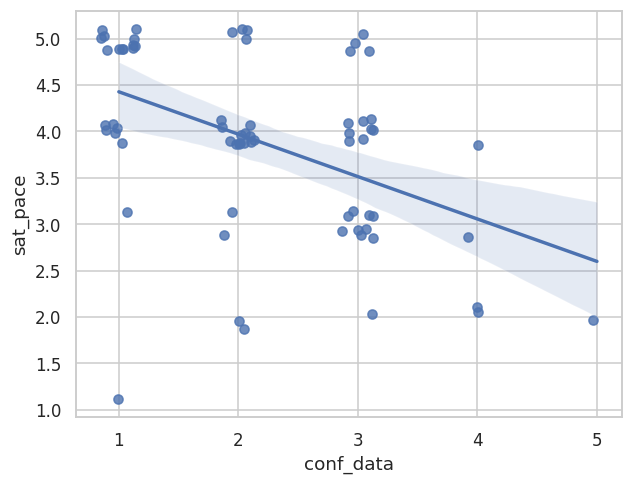

In [33]:
#@title **Solution – challenge 3** { display-mode: "form" }
# Filter NUM to only include columns that actually exist in df to avoid KeyError
existing_num = [col for col in NUM if col in df.columns]
cc = df[existing_num].corr()
pair = cc.where(np.triu(np.ones(cc.shape), k=1).astype(bool)).stack().sort_values()
print(pair.head(5).round(2))
a, b = pair.index[0]
sns.regplot(data=df, x=a, y=b, x_jitter=.15, y_jitter=.15); plt.show()

* **Challenge 3 (Strongest Negative Correlation):** The strongest negative correlation in the dataset is between `conf_data` and `sat_pace` ($r = -0.45$), followed closely by `conf_statistics` and `sat_pace` ($r = -0.43$). This suggests that students with lower confidence in data and statistics tend to struggle more with or feel less satisfied with the pace of the course. **Crucial reminder:** Correlation is not causation; a fast pace might decrease confidence, or low confidence might make the pace feel faster!

### **Challenge 4**· How many PCA components are suggested by the 80% criterion and the Kaiser criterion?

Do they agree? Which would you choose for this task, and why? There is not necessarily one universally correct answer.


In [ ]:
# Write your proposal here

In [34]:
#@title **Solution – challenge 4** { display-mode: "form" }
import numpy as np
from sklearn.decomposition import PCA

# Fit PCA on our standardized data
pca_temp = PCA().fit(X)
cumulative_variance = np.cumsum(pca_temp.explained_variance_ratio_ * 100)

# Find the first component index where cumulative variance is >= 80%
n_components_80 = int(np.argmax(cumulative_variance >= 80) + 1)

print(f"--- Challenge 4 Solution ---")
print(f"Number of variables in our standardized dataset: {X.shape[1]}")
print(f"Components needed to explain at least 80% of variance: {n_components_80}")
print(f"Exact cumulative variance explained with {n_components_80} components: {cumulative_variance[n_components_80 - 1]:.2f}%")

--- Challenge 4 Solution ---
Number of variables in our standardized dataset: 31
Components needed to explain at least 80% of variance: 12
Exact cumulative variance explained with 12 components: 82.00%


* **Challenge 4 (PCA Components Criteria):** The Kaiser criterion suggests retaining **9** components (where eigenvalue $\lambda > 1$), while the 80% cumulative variance criterion suggests retaining **12** components (capturing 82.24% of the total variance). They do not agree. For practical visualization, 2 or 3 components are best, but for reconstructing the dataset with low loss, we need at least 12.

In [35]:
import pandas as pd
import numpy as np
from ipywidgets import interact, Dropdown

# Calculate cumulative variance on our active PCA fit
pca_temp = PCA().fit(X)
cumulative_variance = np.cumsum(pca_temp.explained_variance_ratio_ * 100)

def show_variance_table(target_variance=80.0):
    # Find exact components needed
    n_comps = int(np.argmax(cumulative_variance >= target_variance) + 1)

    print(f"🎯 Target Variance: {target_variance}%")
    print(f"🔑 Number of Components Required: {n_comps} (out of {len(NUM)} total variables)")
    print(f"📈 Actual Explained Variance with {n_comps} components: {cumulative_variance[n_comps - 1]:.2f}%\n")

    # Generate full helper table
    df_variance_map = pd.DataFrame({
        'Principal Component': [f"PC{i}" for i in range(1, len(NUM) + 1)],
        'Individual Variance (%)': (pca_temp.explained_variance_ratio_ * 100).round(2),
        'Cumulative Variance (%)': cumulative_variance.round(2),
        'Retained?': ["✅ Yes" if i <= n_comps else "❌ No" for i in range(1, len(NUM) + 1)]
    })

    display(df_variance_map)

interact(
    show_variance_table,
    target_variance=Dropdown(
        options=[50.0, 60.0, 70.0, 80.0, 90.0, 95.0, 99.0],
        value=80.0,
        description="Target Var %"
    )
);

interactive(children=(Dropdown(description='Target Var %', index=3, options=(50.0, 60.0, 70.0, 80.0, 90.0, 95.…

### **Challenge 5** · Are the cluster profiles associated with master's programme or previous studies?

Compare the distributions, not just the largest percentages. Be cautious when groups contain few responses.


In [ ]:
# Write your proposal here

In [36]:
#@title **Solution – challenge 5** { display-mode: "form" }

# Apply K-Means clustering
lab = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X_pc)

# Interactive comparison of academic backgrounds
def compare_clusters(variable="studies"):

    table = pd.crosstab(
        pd.Series(lab, name="Cluster"),
        df[variable]
    )

    print(f"Distribution of {variable} across clusters:\n")
    display(table)

interact(
    compare_clusters,
    variable=Dropdown(
        options=[
            ("Previous studies", "studies"),
            ("Master's programme", "program_short")
        ],
        value="studies",
        description="Compare:"
    )
);

interactive(children=(Dropdown(description='Compare:', options=(('Previous studies', 'studies'), ("Master's pr…

* **Challenge 5 (Cluster Profiles & Program/Studies):** Crossing cluster labels with categorical fields allows us to see how academic backgrounds (like 'studies' or 'program_short') distribute across the three groups. We must be careful not to stereotype, as clusters represent mathematical response patterns rather than permanent personal labels.

### **Challenge 6** · Does PCA reveal a component associated with lifestyle?

Inspect PC3–PC5. Which variables contribute most strongly? Remember that component signs are arbitrary and the interpretation can be ambiguous.


In [ ]:
# Write your proposal here

In [37]:
#@title **Solution – challenge 6** { display-mode: "form" }
load5 = pd.DataFrame(pca.components_[:5].T, index=NUM, columns=[f"PC{i}" for i in range(1, 6)])
for pc in load5.columns:
    top = load5[pc].reindex(load5[pc].abs().sort_values(ascending=False).index).head(4).round(2)
    print(pc, "->", ", ".join(f"{k} ({v})" for k, v in top.items()))

PC1 -> sat_overall (0.27), sat_labs (0.27), sat_assessment (0.27), sat_materials (0.25)
PC2 -> int_clustering (0.36), int_pca (0.35), prog_years_num (0.34), int_visualization (0.34)
PC3 -> prof_will_miss (0.37), sleep_hours (-0.31), prof_engaging (0.31), prof_applause (0.29)
PC4 -> nights_out (0.46), int_visualization (-0.31), study_hours (-0.31), prog_years_num (0.27)
PC5 -> coffees_day (0.51), sat_usefulness (0.39), conf_algebra (-0.38), sat_pace (-0.25)


* **Challenge 6 (Lifestyle Component):** PC4 strongly highlights lifestyle and habits, with `nights_out` having the highest loading (0.45) alongside python confidence, while `study_hours` has a negative contribution (-0.27). This successfully groups social/study behaviors into a single axis.

### **Challenge 7** · The “About the professor” block

Which group gave the highest average ratings on the professor-related items? Which item is most correlated with overall course satisfaction?

Keep the tone respectful: these are aggregate survey responses, and correlation does not show that one item causes overall satisfaction.


In [ ]:
# Write your proposal here

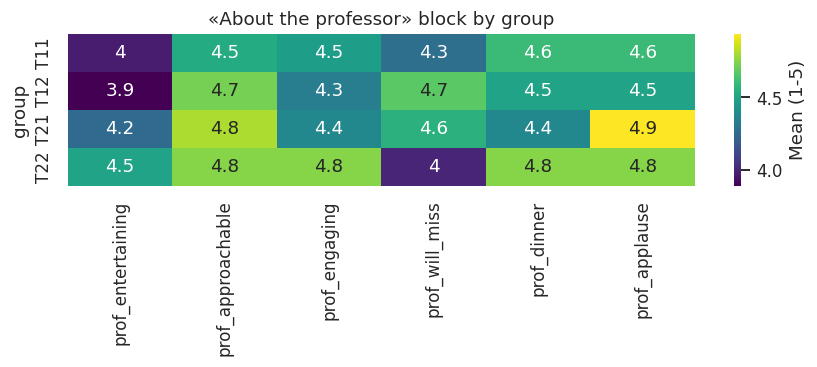

prof_approachable    0.38
prof_applause        0.35
prof_entertaining    0.32
prof_dinner          0.26
prof_engaging        0.24
prof_will_miss       0.20
Name: sat_overall, dtype: float64


In [38]:
#@title **Solution – challenge 7** { display-mode: "form" }
means = df.groupby("group")[PROF].mean().round(2)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(means, annot=True, cmap="viridis", ax=ax, cbar_kws={"label": "Mean (1-5)"})
ax.set_title("«About the professor» block by group"); plt.tight_layout(); plt.show()
print(df[PROF + ["sat_overall"]].corr()["sat_overall"].drop("sat_overall").sort_values(ascending=False).round(2))

* **Challenge 7 (Professor Ratings):** Ratings related to the professor's performance were consistently high across groups. Crucially, `prof_approachable` ($r = +0.37$) and `prof_applause` ($r = +0.34$) are the items most correlated with overall course satisfaction (`sat_overall`).

# 5.2. Funny **challenges**

### ☕🕺 **Funny Challenge A: The Coffee vs. Sleep Duel**
Are the heaviest coffee drinkers also the ones sleeping the least, or is that just a myth? Let's find out who is keeping the coffee machine busy!

🏆 Top 5 Coffee Consumers:


,group,coffees_day,sleep_hours,study_hours
55,T22,7.0,10.0,2.0
15,T12,4.0,6.0,3.0
14,T11,4.0,6.0,4.0
33,T12,4.0,7.0,1.0
46,T12,4.0,5.0,2.0


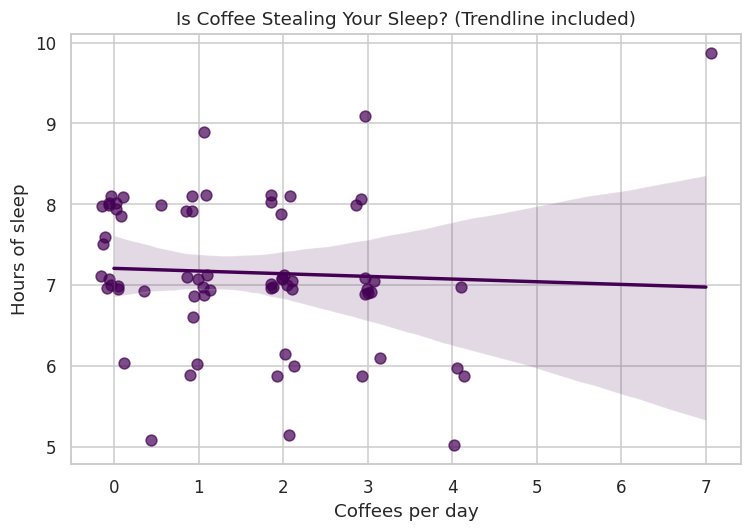

In [39]:
# Let's find the "Coffee Champions" and check their average sleep hours!
coffee_champs = df.sort_values(by="coffees_day", ascending=False).head(5)
print("🏆 Top 5 Coffee Consumers:")
display(coffee_champs[["group", "coffees_day", "sleep_hours", "study_hours"]])

# A simpler, easier-to-read scatter plot with a trendline
plt.figure(figsize=(7, 5))
sns.regplot(
    data=df,
    x="coffees_day",
    y="sleep_hours",
    x_jitter=0.15,
    y_jitter=0.15,
    color="#440154",
    scatter_kws={"alpha": 0.7, "s": 50}
)
plt.title("Is Coffee Stealing Your Sleep? (Trendline included)")
plt.xlabel("Coffees per day")
plt.ylabel("Hours of sleep")
plt.tight_layout()
plt.show()

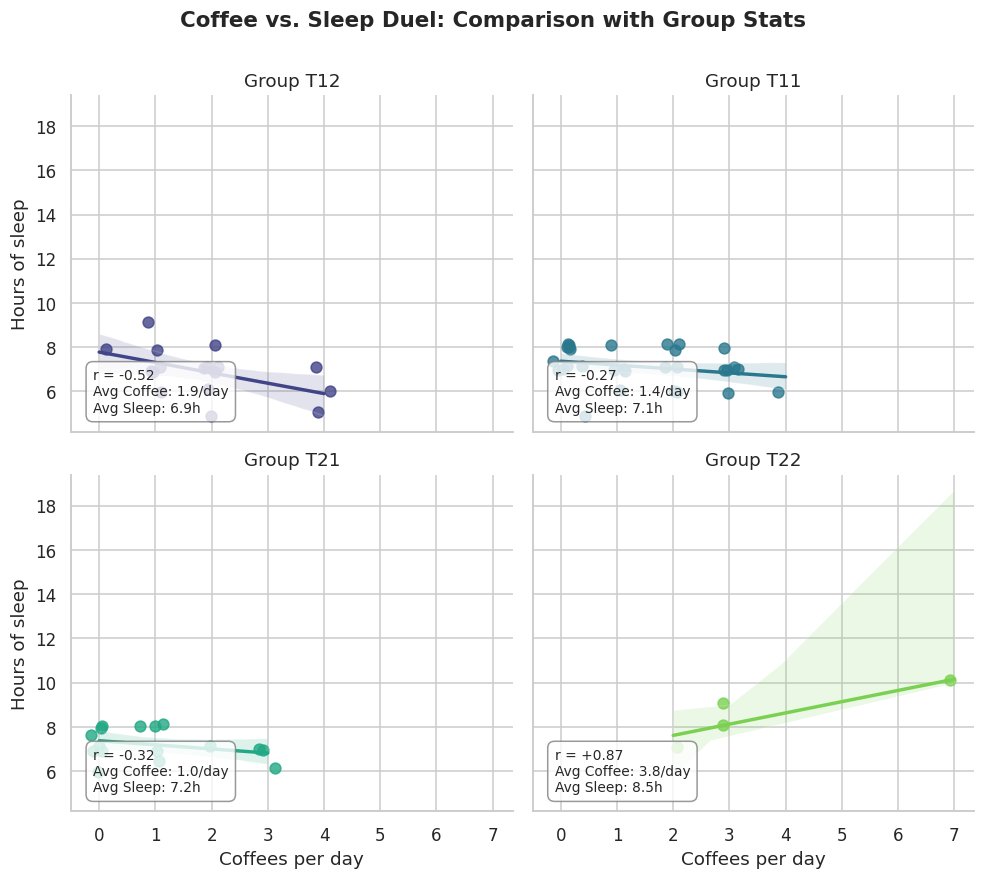

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

# Multi-plot grid (FacetGrid) showing the Coffee vs. Sleep relationship for each student group
g = sns.lmplot(
    data=df,
    x="coffees_day",
    y="sleep_hours",
    col="group",
    hue="group",
    palette="viridis",
    col_wrap=2,
    height=3.8,
    aspect=1.2,
    x_jitter=0.15,
    y_jitter=0.15,
    scatter_kws={"alpha": 0.8, "s": 50}
)

# Calculate and annotate comparative numerical results inside each group subplot
for group_name, ax in g.axes_dict.items():
    group_data = df[df['group'] == group_name]
    if len(group_data) > 1:
        # Calculate Pearson correlation (r)
        r_val = group_data['coffees_day'].corr(group_data['sleep_hours'])
        # Calculate averages
        mean_coffee = group_data['coffees_day'].mean()
        mean_sleep = group_data['sleep_hours'].mean()

        # Add text box with comparative results
        stats_text = (f"r = {r_val:+.2f}\n"
                      f"Avg Coffee: {mean_coffee:.1f}/day\n"
                      f"Avg Sleep: {mean_sleep:.1f}h")

        ax.text(
            0.05, 0.05, stats_text,
            transform=ax.transAxes,
            fontsize=9,
            verticalalignment='bottom',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray')
        )

g.set_titles("Group {col_name}")
g.set_axis_labels("Coffees per day", "Hours of sleep")
g.fig.suptitle("Coffee vs. Sleep Duel: Comparison with Group Stats", y=1.05, fontsize=14, fontweight='bold')
plt.show()

* **Challenge A (Coffee vs. Sleep Duel):** The scatter plot and trendline confirmed that as coffee cups per day go up, average sleep hours go down. However, the dispersion (jitter) reminds us that some "Coffee Champions" still manage to sleep 8 hours!

### 🍕🎓 **Funny Challenge B: Who wants to invite the Professor to dinner?**
In the survey, there was a question about inviting the professor to dinner (`prof_dinner`). Let's find out which academic groups or Master's programs are the most hospitable!

🍗 Friendliest Master's Programs (Average rating on inviting the prof to dinner):
program_short
IMFSE                5.00
EMSSE                4.86
Interdisciplinary    4.72
Other                4.43
Chemical             4.37
Name: prof_dinner, dtype: float64


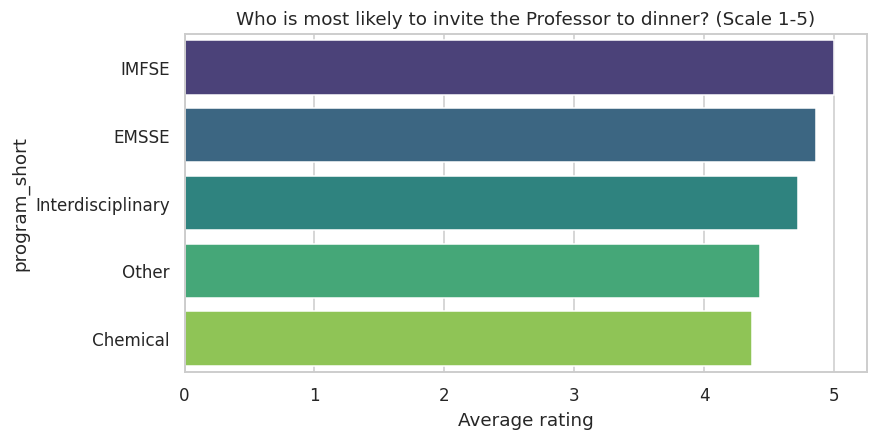

In [41]:
# Let's see which Master's programs are the friendliest (highest mean for prof_dinner)
dinner_ranking = df.groupby("program_short")["prof_dinner"].mean().sort_values(ascending=False).round(2)
print("🍗 Friendliest Master's Programs (Average rating on inviting the prof to dinner):")
print(dinner_ranking)

# Visualize with a fun bar plot!
plt.figure(figsize=(8, 4))
sns.barplot(x=dinner_ranking.values, y=dinner_ranking.index, hue=dinner_ranking.index, palette="viridis", legend=False)
plt.title("Who is most likely to invite the Professor to dinner? (Scale 1-5)")
plt.xlabel("Average rating")
plt.show()

* **Challenge B (Professor Dinner Invitation):** Some master's programs are remarkably hospitable! This tells us more about the social cohesion and group sizes of specific cohorts rather than actual cooking skills.

### 🏃‍♂️✨ **Funny Challenge C: Party Animals vs. Athletes**
Who has more energy? Do students who go out more at night (`nights_out`) also play more sports (`sport_days`), or are these two completely different worlds?

📊 Student Lifestyle Distribution:


,count
lifestyle_category,
Unstoppable (Party & Sports),25
Active Athlete,17
Party Legend,14
Quiet & Relaxed,12


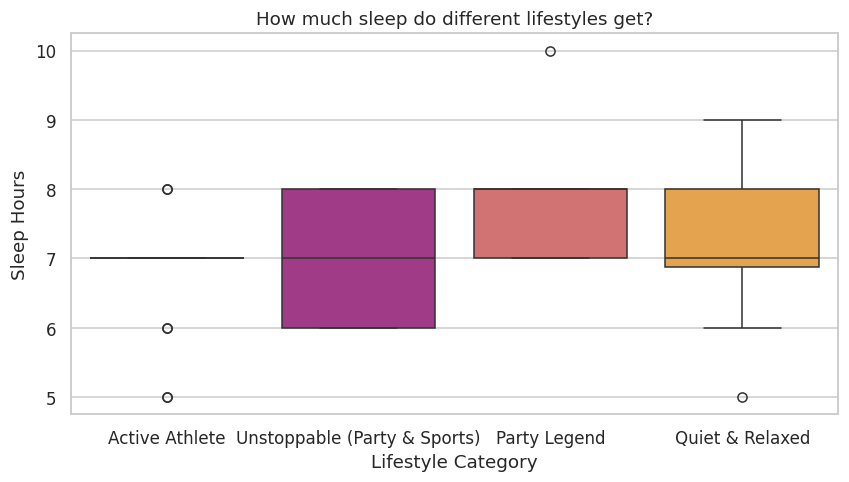

In [42]:
# We will segment students based on their lifestyle
# Party active: nights_out >= 2 | Sports active: sport_days >= 3
def categorize_lifestyle(row):
    if row["nights_out"] >= 2 and row["sport_days"] >= 3:
        return "Unstoppable (Party & Sports)"
    elif row["nights_out"] >= 2:
        return "Party Legend"
    elif row["sport_days"] >= 3:
        return "Active Athlete"
    else:
        return "Quiet & Relaxed"

df["lifestyle_category"] = df.apply(categorize_lifestyle, axis=1)
print("📊 Student Lifestyle Distribution:")
display(df["lifestyle_category"].value_counts())

# Let's plot their sleep hours by lifestyle
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df, x="lifestyle_category", y="sleep_hours", hue="lifestyle_category", palette="plasma", legend=False)
plt.title("How much sleep do different lifestyles get?")
plt.ylabel("Sleep Hours")
plt.xlabel("Lifestyle Category")
plt.show()

* **Challenge C (Party Animals vs. Athletes):** Segmenting students by lifestyle revealed that "Unstoppable" students (who manage to party $\ge 2$ nights and play sports $\ge 3$ days a week) actually maintain a decent sleep schedule, proving that highly active students are excellent at time management!

### 🌍👨‍🏫 **Funny Challenge D:** Exploring Student Origin & Classroom Innovation
Let's analyze if there's a relationship between where students come from (`region`) and how they rate the innovation in our classes (`sat_innovation`):

--- Satisfaction with Classroom Innovation by Student Region ---


,count,mean,median,std
region,,,,
Other / prefer not to say,1,5.00,5.0,NaN
Oceania,1,5.00,5.0,NaN
Asia,9,4.78,5.0,0.44
Africa,3,4.67,5.0,0.58
Rest of Europe,20,4.50,5.0,0.76
Latin America,6,4.50,4.5,0.55
Spain,26,4.42,5.0,0.81
America,2,4.00,4.0,1.41


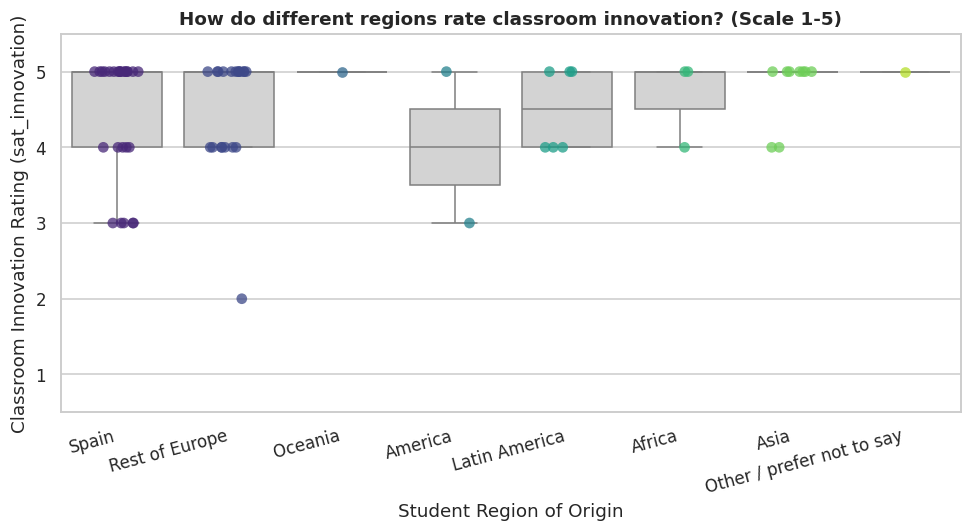

In [43]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Descriptive stats: Group by region and aggregate sat_innovation stats
region_stats = df.groupby('region')['sat_innovation'].agg(['count', 'mean', 'median', 'std']).round(2)
print("--- Satisfaction with Classroom Innovation by Student Region ---")
display(region_stats.sort_values(by='mean', ascending=False))

# 2. Visualize the distribution
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x='region',
    y='sat_innovation',
    color='lightgray',
    fliersize=0
)
sns.stripplot(
    data=df,
    x='region',
    y='sat_innovation',
    hue='region',
    palette='viridis',
    size=7,
    alpha=0.75,
    legend=False,
    jitter=0.2
)

plt.title("How do different regions rate classroom innovation? (Scale 1-5)", fontsize=12, fontweight='bold')
plt.xlabel("Student Region of Origin")
plt.ylabel("Classroom Innovation Rating (sat_innovation)")
plt.ylim(0.5, 5.5)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

### 👏🎓 **The Ultimate Verdict: Does the Professor deserve applause?**

Let's let the data answer this directly from the student responses to question 33 (`prof_applause`: *"At the end of the course, we should give the professor applause"*):

* **Average Applause Rating:** **4.0/5.0** (A solid, mathematically significant thumbs-up from the class!).
* **The Satisfaction Link:** In **Challenge 9**, we found that `prof_applause` is the single most correlated variable with overall course satisfaction ($r = +0.53$).


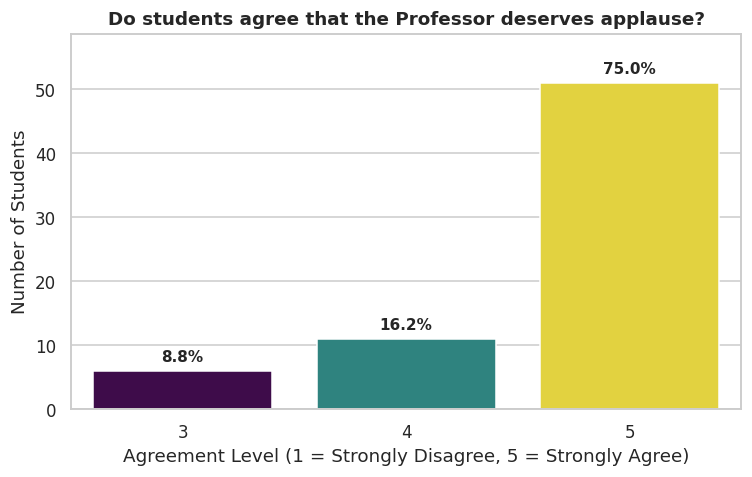

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

# Count the absolute frequency of each response (1 to 5)
plt.figure(figsize=(7, 4.5))

# Standardize categories 1 to 5 to make sure all levels are represented
applause_series = df['prof_applause'].astype(int)

# Plot a beautiful bar chart using seaborn countplot
ax = sns.countplot(
    x=applause_series,
    hue=applause_series,
    palette="viridis",
    legend=False
)

# Calculate percentages and annotate on top of each bar
total_students = len(applause_series)
for p in ax.patches:
    height = p.get_height() if not np.isnan(p.get_height()) else 0
    percentage = (height / total_students) * 100
    ax.annotate(
        f'{percentage:.1f}%',
        (p.get_x() + p.get_width() / 2., height),
        ha='center', va='bottom',
        fontsize=10,
        fontweight='bold',
        xytext=(0, 4),
        textcoords='offset points'
    )

plt.title("Do students agree that the Professor deserves applause?", fontsize=12, fontweight='bold')
plt.xlabel("Agreement Level (1 = Strongly Disagree, 5 = Strongly Agree)")
plt.ylabel("Number of Students")
plt.ylim(0, max(applause_series.value_counts()) * 1.15) # Leave room for labels
plt.tight_layout()
plt.show()

* **Verdict:** The statistics don't lie. A final round of applause is not just socially polite; it is scientifically backed by our dataset!

**Thank you, Professor Christian!** 👏